# 08_01 — Shot-to-shot jitter models: ridge, RNN, GRU

Like 08, this estimates `BCM_GUN` of a shot from **the same shot's** features (a "virtual BCM", not a forecast). The
difference is how the charge is split:

```
charge = slow level x (1 + fast jitter)
```

- **The slow level** is the mean of the previous 50 BCM readings (in logs). It drifts over minutes to hours and is
  taken as known: this is the case where the BCM worked until the previous shot.
- **The fast jitter** is what the models predict: log(BCM / level), the shot-to-shot scatter of a few %. It is
  predicted from each feature's own jitter, the feature against the mean of its previous 50 readings.

Without the level, the models of 08 have to learn the drift and the jumps between segments from the features, which
change their gain from run to run. With it, they only learn the small shot-to-shot part. A plain-language write-up
is in `docs/charge_models_explained.md`.

**Models:** a ridge on the current shot; a plain RNN and a GRU on the last `L` shots; and the GRU learning the ridge's
residual (ridge + GRU).

**Data:** the same per-segment datasets as 08 (`results/datasets/`; the file layout is described there). Other
settings differ from 08:
- **One model per charge regime,** trained on all of that regime's segments together.
- **Split:** within each segment, the first 90 % of the shots train and the last 10 % test.

The script version, `scripts/jitter_sequence.py`, runs on the pulse-grid tables. It adds clex, the laser scope and
the windowed beam-loading step, and its numbers are in `scripts/README.md`.

In [1]:
import json
from pathlib import Path

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import torch
from sklearn.linear_model import RidgeCV
from sklearn.model_selection import KFold

REPO = Path.cwd().parent if Path.cwd().name == "notebooks" else Path.cwd()
DATASETS = REPO / "results" / "datasets"

# the three regimes of the clean data (results/data_labelling/stitched_bcm.png), by segment number of the manifest
REGIMES = {"low charge": [0, 2, 3, 4], "high, repetitive": [5], "high, non-repetitive": [1, 6, 7]}
REGIME = "high, non-repetitive"   # the regime worked through step by step below
TEST_FRAC = 0.1    # the last 10 % of each segment's shots are the test set
SLOW = 50          # shots in the trailing level (1 min at 0.83 Hz)
LINEAR = {"PGLA_drop", "BTV_mean_x", "BTV_tilt"}   # can be <= 0: used as they are, the others as logs
DARK = 0.3         # a camera frame below 30 % of the recent intensity is a glitch, not beam

manifest = json.loads((DATASETS / "manifest.json").read_text())
FEATURES = manifest["features"]
CAMERA = [f for f in FEATURES if f.startswith(("BTV_", "SVD_"))]
GROUP = {f: "camera" if f in CAMERA else f for f in FEATURES}      # one missing flag per instrument
torch.set_num_threads(4)                                            # more threads are slower for networks this small
print("features:", FEATURES)

features: ['lab_laser_power', 'PGLA_drop', 'SVD_s1', 'BTV_intensity', 'SVD_s5', 'SVD_s6', 'SVD_s4', 'PKI15A', 'BTV_tilt', 'BTV_mean_x']


## Load all segments

Each regime's model learns from all of its segments, so all datasets are loaded into one DataFrame, one row per shot,
in time order.

**Rows kept:** `complete` rows with a positive BCM reading.
- **BCM lost:** shots where the BCM is under half its segment median while the camera sees the beam (intensity above
  half its median) are dropped. Segment 5 has ~70 such shots with the BCM at 0.001–0.02 nC. Kept, they wreck the
  ridge (a negative jitter explained on segment 5) and drag down the trailing level of the next 50 shots.
  - Only high-charge segments (median > 1 nC) are checked, as in `scripts/run_data.py`.
  - The low-charge dips are kept, as in the scripts.
- Frozen camera images are set to NaN rather than dropped. The BCM and the laser meter still read on those shots.
- The jitter is computed over consecutive kept rows. Dropping rows is fine here, because no model assumes a fixed
  time step.

**Dark frames:** a few % of the camera images are near-black glitches while the BCM and the laser are normal: under
30 % of the median of the previous 50 frames, with the laser meter above 70 % of its own median. Their camera features
are set to NaN too. The test uses only past frames.

In [2]:
parts, n_lost = [], []
for info in manifest["segments"]:
    d = np.load(DATASETS / info["file"])
    p = pd.DataFrame(d["X"], columns=d["features"])
    p["BCM_GUN"], p["seg"] = d["y"], info["segment"]
    p.loc[d["btv_frozen"], CAMERA] = np.nan
    med = p["BCM_GUN"].median()
    lost = (med > 1) & (p["BCM_GUN"] < 0.5 * med) & (p["BTV_intensity"] > 0.5 * p["BTV_intensity"].median())
    n_lost.append(lost.sum())
    p = p[d["complete"] & (d["y"] > 0) & ~lost].reset_index(drop=True)
    recent = lambda v: v / v.shift(1).rolling(50, min_periods=5).median()
    dark = (recent(p["BTV_intensity"]) < DARK) & (recent(p["lab_laser_power"]) > 0.7)
    p.loc[dark, CAMERA] = np.nan
    p["dark"] = dark
    p["test"] = np.arange(len(p)) >= int(len(p) * (1 - TEST_FRAC))
    parts.append(p)
df = pd.concat(parts, ignore_index=True)
df["regime"] = df["seg"].map({s: r for r, segs in REGIMES.items() for s in segs})

print("BCM-lost shots dropped per segment:", {i["segment"]: int(n) for i, n in zip(manifest["segments"], n_lost)})
df.groupby("seg").agg(regime=("regime", "first"), shots=("BCM_GUN", "size"), test=("test", "sum"),
                      BCM_mean_nC=("BCM_GUN", "mean"), dark_frames=("dark", "mean")).round(3)

BCM-lost shots dropped per segment: {0: 0, 1: 5, 2: 0, 3: 0, 4: 0, 5: 75, 6: 0, 7: 1}


,regime,shots,test,BCM_mean_nC,dark_frames
seg,,,,,
0,low charge,6026,603,0.223,0.010
1,"high, non-repetitive",19394,1940,4.830,0.014
2,low charge,199,20,0.144,0.010
3,low charge,7091,710,0.122,0.008
4,low charge,4496,450,0.101,0.012
5,"high, repetitive",19924,1993,5.481,0.002
6,"high, non-repetitive",4099,410,5.506,0.000
7,"high, non-repetitive",1998,200,10.096,0.003


## Split every signal into slow and fast

For every signal, **slow** is the mean of its previous `SLOW` readings in the same segment. It uses only the past,
because a centred average would use future shots that a real-time estimate does not have.
- **Logs:** the jitter is log(reading) − slow, so 3 % means the same at 0.1 nC and at 10 nC. The three signals in
  `LINEAR` can be ≤ 0 and are used as they are.
- **Missing readings:** a missing reading has jitter 0 (no information), and a flag per instrument marks it.

**The target** is the BCM's own jitter, log(BCM) − the mean log BCM of the previous `SLOW` shots. The first 5 shots of
each segment have no level yet and are not used.

14 inputs; 56861 training shots (5690 of them for early stopping), 6326 test shots


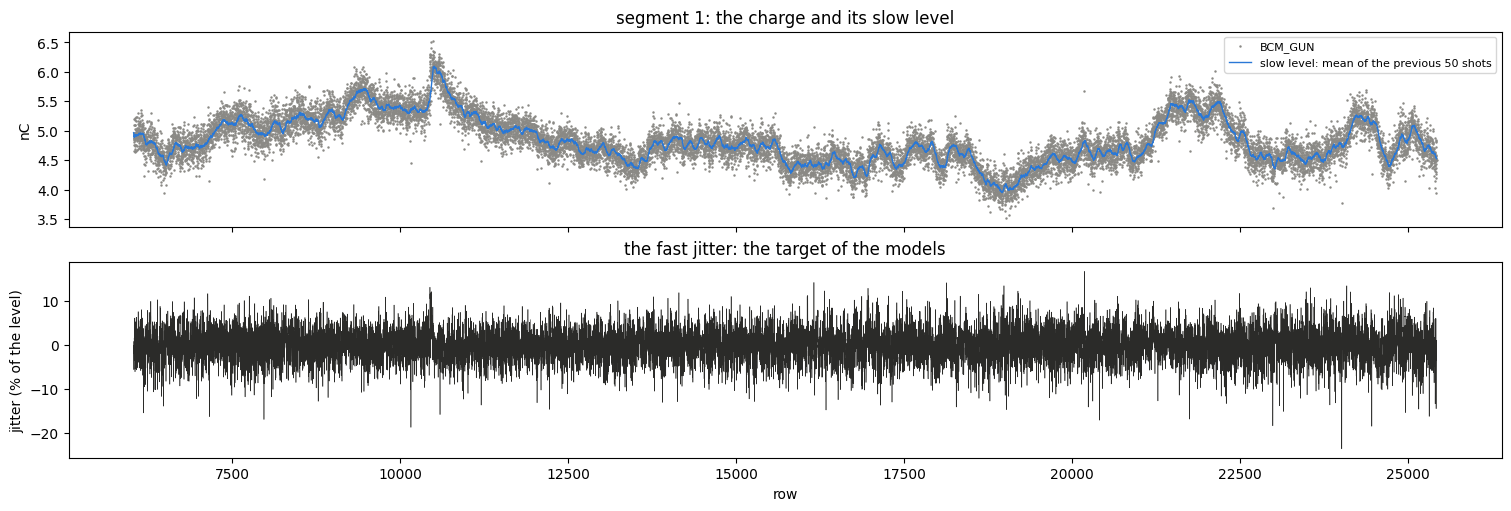

In [3]:
def trailing(v):
    """Mean of the previous SLOW values in the same segment (missing ones skipped); NaN until 5 are there."""
    return v.groupby(df["seg"]).transform(lambda c: c.shift(1).rolling(SLOW, min_periods=5).mean())


log_bcm = np.log(df["BCM_GUN"])
level = trailing(log_bcm)                     # the slow level (log nC)
jitter = log_bcm - level                      # the target
raw = pd.DataFrame({f: df[f] if f in LINEAR else np.log(df[f].where(df[f] > 0)) for f in FEATURES})
X = (raw - trailing(raw)).fillna(0)          # the inputs: each feature's own jitter
for g in sorted(set(GROUP.values())):
    X[f"{g} missing"] = raw[[f for f in FEATURES if GROUP[f] == g]].isna().any(axis=1).astype(float)

ok = level.notna()
train = ~df["test"] & ok
k = train.groupby(df["seg"]).cumsum()
stop = train & (k > 0.9 * k.groupby(df["seg"]).transform("max"))   # end of each training part: early stopping
print(f"{X.shape[1]} inputs; {train.sum()} training shots ({stop.sum()} of them for early stopping), "
      f"{(df['test'] & ok).sum()} test shots")

s = REGIMES[REGIME][0]
i = df.index[(df["seg"] == s) & ok]
fig, (ax1, ax2) = plt.subplots(2, 1, figsize=(15, 5), sharex=True, layout="constrained")
ax1.plot(i, df["BCM_GUN"][i], ".", ms=1.5, color="#8a8985", label="BCM_GUN")
ax1.plot(i, np.exp(level[i]), color="#2a78d6", lw=1, label=f"slow level: mean of the previous {SLOW} shots")
ax2.plot(i, 100 * jitter[i], color="#2b2b29", lw=0.4)
ax1.set(ylabel="nC", title=f"segment {s}: the charge and its slow level")
ax2.set(ylabel="jitter (% of the level)", xlabel="row", title="the fast jitter: the target of the models")
ax1.legend(fontsize=8)
plt.show()

Scores on each test segment of the regime:
- **MAE (pC):** the mean absolute error of the total charge, level × e^(predicted jitter), against the BCM.
- **Jitter explained:** 1 − mean square of (jitter − prediction) / mean square of the jitter. 100 % is perfect, and
  0 % is no better than predicting no jitter.

The reference model is "trailing level only": jitter 0, i.e. the charge is the mean of the previous 50 shots.

In [4]:
R = (df["regime"] == REGIME) & ok                 # this regime's usable rows
results, predictions = {}, {}


def score(name, pred, segs=REGIMES[REGIME]):
    """pred: predicted jitter (Series on the regime's rows) -> MAE (pC) and jitter explained per test segment."""
    predictions[name] = pred
    out = {}
    for s in segs:
        i = df.index[df["test"] & ok & (df["seg"] == s)]
        e = np.exp(level[i] + pred[i]) - df["BCM_GUN"][i]
        out[("MAE (pC)", s)] = 1000 * e.abs().mean()
        out[("jitter explained %", s)] = 100 * (1 - ((jitter[i] - pred[i]) ** 2).mean() / (jitter[i] ** 2).mean())
    results[name] = out
    print(name + ": " + ", ".join(f"seg {s} {out[('MAE (pC)', s)]:.1f} pC, {out[('jitter explained %', s)]:.1f} %" for s in segs))


score("trailing level only", pd.Series(0.0, df.index[R]))

trailing level only: seg 1 143.3 pC, 0.0 %, seg 6 122.4 pC, 0.0 %, seg 7 491.5 pC, 0.0 %


## Ridge regression

`jitter ≈ w·x + b` on the current shot's input jitters, least squares with an L2 penalty on `w` (Tikhonov
regularisation). The penalty keeps the fit stable when several inputs say almost the same thing, like the six camera
SVD values.
- `alphas`: the penalties tried. `RidgeCV` picks the best by cross-validation on the training shots.
- `cv=KFold(5)`: the folds are 5 contiguous blocks, not shuffled. Neighbouring shots are correlated, so a random fold
  would put near-copies of its validation shots into training.

In [5]:
ridge = RidgeCV(alphas=np.logspace(-3, 4, 30), cv=KFold(5)).fit(X[train & R], jitter[train & R])
print(f"alpha {ridge.alpha_:.3g}")
score("ridge", pd.Series(ridge.predict(X[R]), df.index[R]))

# change of the jitter per standard deviation of each input, in % of the level
(pd.Series(ridge.coef_, index=X.columns) * X[train & R].std() * 100).sort_values(key=abs, ascending=False).rename("% per std").round(2)

alpha 0.788
ridge: seg 1 109.4 pC, 34.7 %, seg 6 62.2 pC, 69.3 %, seg 7 240.8 pC, 85.9 %


BTV_intensity              2.21
lab_laser_power            1.43
SVD_s6                    -0.80
BTV_mean_x                -0.59
BTV_tilt                  -0.45
SVD_s1                    -0.39
PGLA_drop                  0.10
SVD_s5                    -0.07
SVD_s4                     0.07
camera missing            -0.01
PKI15A                     0.01
PGLA_drop missing          0.00
PKI15A missing             0.00
lab_laser_power missing    0.00
Name: % per std, dtype: float64

## RNN and GRU (recurrent neural networks)

Both read a window of the last `L` shots' input jitters, one shot after the other, and keep a hidden state of `H`
numbers as a running memory. The prediction is a linear function of the state after the current shot.
- **RNN** (`torch.nn.RNN`): the state is updated as tanh(W·state + U·input).
- **GRU** (`torch.nn.GRU`): adds two gates that decide how much of the old state to keep and how much to overwrite.
  It is usually easier to train on long windows.

**Inputs:** a window never reaches into the previous segment. Steps before the segment's start are zero ("no
jitter").

**Training,** as in `scripts/gru_forecast.py`:
- **Scaling:** each input is divided by its training standard deviation, and clipped at ±`CLIP`, so a wild reading
  cannot saturate the network.
- **Output layer:** starts at zero, so an untrained network predicts "no jitter". Early stopping may keep that
  untrained state if training never beats it.
- **Loss:** L1, i.e. the mean absolute error, the same metric as the MAE. Optimiser Adam, `LR`, batches of `BATCH`
  windows.
- **Early stopping:** on the last 10 % of each segment's training part, never the test set. Training stops after
  `PATIENCE` epochs without improvement, and the best epoch is kept.
- **Seeds:** the predictions of `SEEDS` (different random initial weights) are averaged.

Training one model with 3 seeds takes 10–40 s for `L = 16`.

In [6]:
L, H = 16, 32
SEEDS = (0, 1, 2)
BATCH, EPOCHS, PATIENCE, LR, CLIP = 256, 40, 5, 1e-3, 5

pos = df.groupby("seg").cumcount().to_numpy()                       # row number within its segment
A = torch.from_numpy(np.vstack([X.to_numpy(), np.zeros((1, X.shape[1]))]).astype(np.float32))   # + a zero pad row


def windows(L):
    """rows x L indices into A: the shot and the L-1 before it; the pad row before the segment's start."""
    lag = np.arange(L - 1, -1, -1)
    return np.where(pos[:, None] >= lag, np.arange(len(df))[:, None] - lag, len(df))


class Seq(torch.nn.Module):
    def __init__(self, cell, scale):
        super().__init__()
        self.register_buffer("scale", scale)                        # per-input training std
        self.rnn = getattr(torch.nn, cell)(len(scale), H, batch_first=True)
        self.out = torch.nn.Linear(H, 1)

    def forward(self, x):
        return self.out(self.rnn((x / self.scale).clamp(-CLIP, CLIP))[0][:, -1]).squeeze(-1)


def predict(model, I):
    with torch.no_grad():
        return torch.cat([model(A[b]) for b in torch.from_numpy(I).split(4096)]).numpy()


def fit(cell, I, y, tr, va, seed):
    """One network on the windows I[tr] -> y[tr], early-stopped on I[va]; returns the model and its epochs."""
    torch.manual_seed(seed)
    model = Seq(cell, A[tr].std(0).clamp(min=1e-6))
    torch.nn.init.zeros_(model.out.weight); torch.nn.init.zeros_(model.out.bias)
    opt = torch.optim.Adam(model.parameters(), LR)
    It, yt = torch.from_numpy(I[tr]), torch.from_numpy(y[tr])
    best, state, wait = np.mean(np.abs(y[va])), {k: t.clone() for k, t in model.state_dict().items()}, 0
    for epoch in range(EPOCHS):
        model.train()
        for b in torch.randperm(len(It)).split(BATCH):
            loss = (model(A[It[b]]) - yt[b]).abs().mean()
            opt.zero_grad(); loss.backward(); opt.step()
        model.eval()
        v = np.mean(np.abs(predict(model, I[va]) - y[va]))
        if v < best:
            best, state, wait = v, {k: t.clone() for k, t in model.state_dict().items()}, 0
        else:
            wait += 1
            if wait >= PATIENCE:
                break
    model.load_state_dict(state)
    return model, epoch + 1


def net(cell, R, L, base=None):
    """cell ('RNN' or 'GRU') on windows of L shots, trained on the regime R's training rows to predict the jitter
    (minus base, a prediction it then corrects), averaged over SEEDS -> predicted jitter on the regime's rows."""
    I = windows(L)
    b = np.zeros(len(df), np.float32) if base is None else base.reindex(df.index).fillna(0).to_numpy(np.float32)
    y = jitter.fillna(0).to_numpy(np.float32) - b
    tr, va = np.flatnonzero(train & ~stop & R), np.flatnonzero(stop & R)
    preds, epochs = [], []
    for seed in SEEDS:
        model, ep = fit(cell, I, y, tr, va, seed)
        preds.append(predict(model, I[R.to_numpy()])); epochs.append(ep)
    print(f"  {cell}, L={L}{', on a base' * (base is not None)}: epochs {epochs}")
    return pd.Series(b[R.to_numpy()] + np.mean(preds, 0), df.index[R])


I = windows(L)
assert np.array_equal(A[I[:, -1]].numpy(), X.to_numpy(np.float32))          # the newest step is the current shot
assert (I[pos < L - 1, 0] == len(df)).all()                                # steps before the segment are padded

In [7]:
score("RNN", net("RNN", R, L))

  RNN, L=16: epochs [29, 15, 29]
RNN: seg 1 52.2 pC, 78.8 %, seg 6 41.0 pC, 88.9 %, seg 7 295.2 pC, 24.5 %


In [8]:
score("GRU", net("GRU", R, L))

  GRU, L=16: epochs [17, 39, 21]
GRU: seg 1 51.0 pC, 79.3 %, seg 6 39.7 pC, 89.9 %, seg 7 289.3 pC, 29.7 %


## Ridge + GRU

The networks clip their inputs and their units saturate (tanh), so they cannot follow a jump far outside what they
saw in training. Seg 7 ends with a jump to 18 nC (+55 %). In the script's run the GRU stops at about +15 % there,
while the ridge extrapolates.

Here the GRU learns only the ridge's residual, and the prediction is ridge + GRU. The ridge carries the large linear
part and keeps extrapolating, and the GRU adds the non-linear correction. Its zero-initialised output means it starts
as the plain ridge.

In [9]:
score("ridge + GRU", net("GRU", R, L, base=predictions["ridge"]))

  GRU, L=16, on a base: epochs [39, 29, 22]
ridge + GRU: seg 1 52.6 pC, 75.9 %, seg 6 38.1 pC, 90.7 %, seg 7 163.9 pC, 89.9 %


## Comparison

Left: the test shots of each segment of the regime, as jitter, measured and predicted. Right: predicted against
measured jitter.

,MAE (pC),jitter explained %,MAE (pC),jitter explained %,MAE (pC),jitter explained %
,1,1,6,6,7,7
trailing level only,143.3,0.0,122.4,0.0,491.5,0.0
ridge,109.4,34.7,62.2,69.3,240.8,85.9
RNN,52.2,78.8,41.0,88.9,295.2,24.5
GRU,51.0,79.3,39.7,89.9,289.3,29.7
ridge + GRU,52.6,75.9,38.1,90.7,163.9,89.9


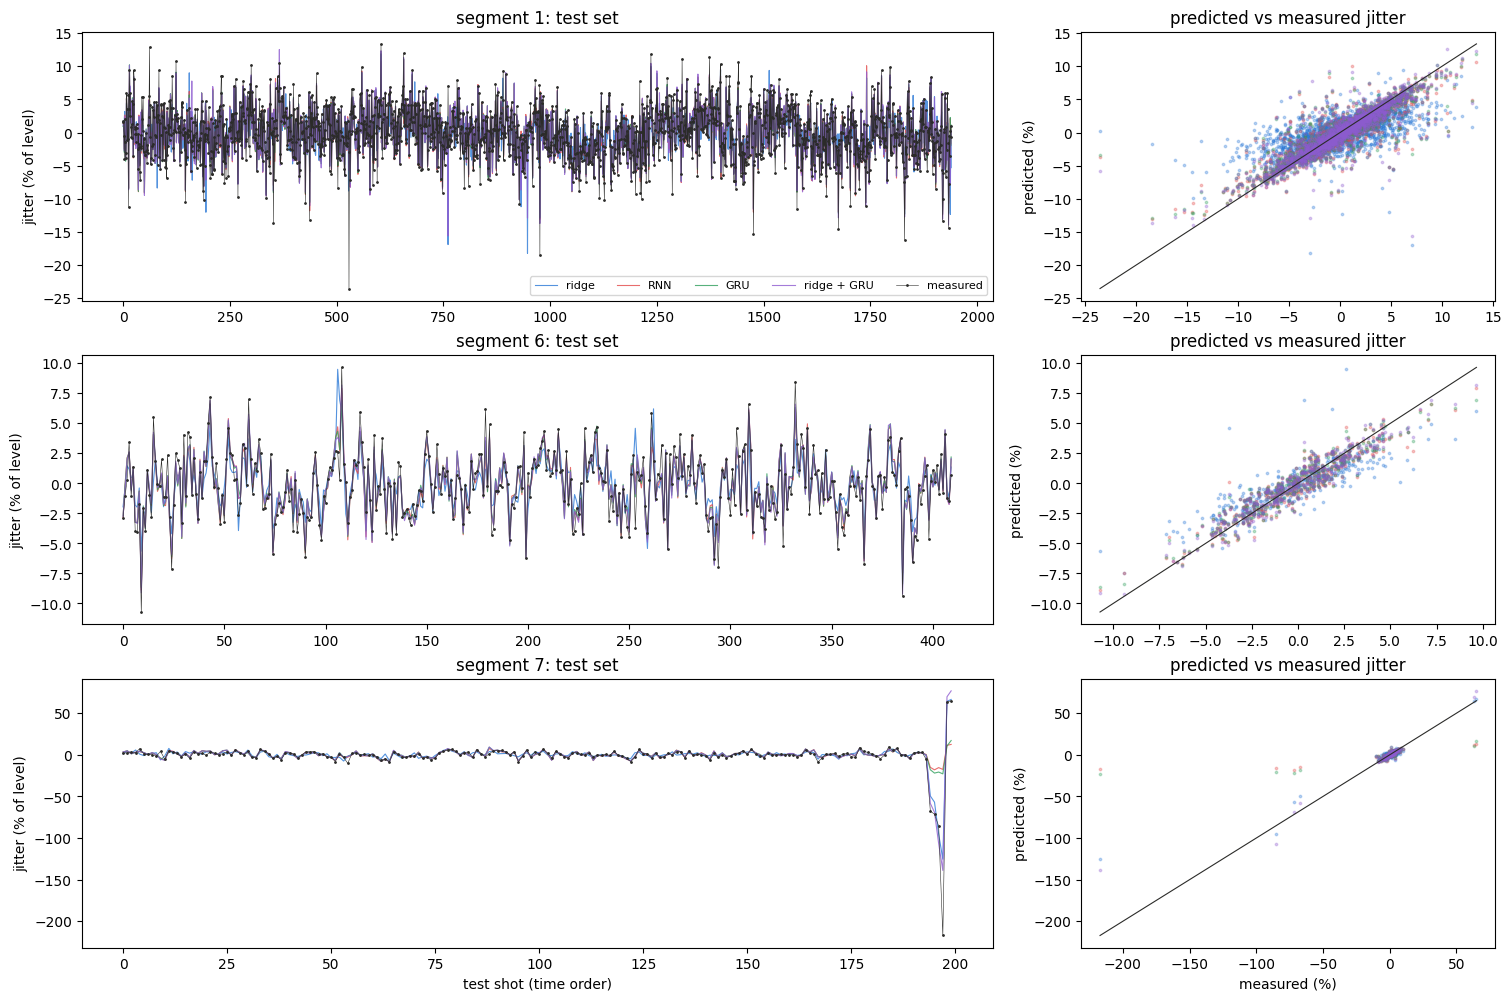

In [10]:
display(pd.DataFrame(results).T.round(1))

COLORS = {"ridge": "#2a78d6", "RNN": "#e34948", "GRU": "#2e9e5b", "ridge + GRU": "#8e5bd0"}
segs = REGIMES[REGIME]
fig, axes = plt.subplots(len(segs), 2, figsize=(15, 3.3 * len(segs)), gridspec_kw={"width_ratios": [2.2, 1]},
                         layout="constrained", squeeze=False)
for (ax1, ax2), s in zip(axes, segs):
    i = df.index[df["test"] & ok & (df["seg"] == s)]
    for name, color in COLORS.items():
        ax1.plot(np.arange(len(i)), 100 * predictions[name][i], color=color, lw=0.8, alpha=0.8, label=name)
        ax2.scatter(100 * jitter[i], 100 * predictions[name][i], s=3, color=color, alpha=0.3)
    ax1.plot(np.arange(len(i)), 100 * jitter[i], ".-", color="#2b2b29", lw=0.4, ms=2, label="measured")   # on top
    lim = 100 * np.array([jitter[i].min(), jitter[i].max()])
    ax2.plot(lim, lim, color="#2b2b29", lw=0.8)
    ax1.set(ylabel="jitter (% of level)", title=f"segment {s}: test set")
    ax2.set(ylabel="predicted (%)", title="predicted vs measured jitter")
axes[0, 0].legend(fontsize=8, ncols=5)
axes[-1, 0].set_xlabel("test shot (time order)")
axes[-1, 1].set_xlabel("measured (%)")
plt.show()

## All regimes

The same models and settings on every regime, each trained on its own segments. This takes about 5 minutes.
- **Comparing MAE:** the charge level differs a lot between segments (0.1 nC to 10 nC), so compare the MAE within a
  row, or against `BCM mean`.
- **Comparing jitter explained:** it is comparable across rows.

The best model per segment is in bold. Segment 2 has only 20 test shots, so its scores are noisy.

In [11]:
MODELS = ["trailing level only", "ridge", "RNN", "GRU", "ridge + GRU"]
rows, curves = [], {}
for rname, segs in REGIMES.items():
    print(rname)
    Rr = (df["regime"] == rname) & ok
    m = RidgeCV(alphas=np.logspace(-3, 4, 30), cv=KFold(5)).fit(X[train & Rr], jitter[train & Rr])
    preds = {"trailing level only": pd.Series(0.0, df.index[Rr]), "ridge": pd.Series(m.predict(X[Rr]), df.index[Rr])}
    preds["RNN"], preds["GRU"] = net("RNN", Rr, L), net("GRU", Rr, L)
    preds["ridge + GRU"] = net("GRU", Rr, L, base=preds["ridge"])
    for s in segs:
        i = df.index[df["test"] & ok & (df["seg"] == s)]
        row = {("", "regime"): rname, ("", "train"): (train & (df["seg"] == s)).sum(), ("", "test"): len(i),
               ("", "BCM mean (nC)"): df["BCM_GUN"][i].mean()}
        for name in MODELS:
            row[("MAE (pC)", name)] = 1000 * (np.exp(level[i] + preds[name][i]) - df["BCM_GUN"][i]).abs().mean()
            row[("jitter explained %", name)] = 100 * (1 - ((jitter[i] - preds[name][i]) ** 2).mean() / (jitter[i] ** 2).mean())
        rows.append(pd.Series(row, name=s))
        curves[s] = (df["BCM_GUN"][i].to_numpy(), {n: np.exp(level[i] + preds[n][i]).to_numpy() for n in MODELS})

summary = pd.DataFrame(rows).rename_axis("segment").sort_index()
summary.columns = pd.MultiIndex.from_tuples(summary.columns)
mae, je = summary["MAE (pC)"].columns, summary["jitter explained %"].columns
(summary.style
    .format("{:.0f}", subset=[("", "train"), ("", "test")])
    .format("{:.3f}", subset=[("", "BCM mean (nC)")])
    .format("{:.1f}", subset=[("MAE (pC)", m) for m in mae] + [("jitter explained %", m) for m in je])
    .highlight_min(subset=[("MAE (pC)", m) for m in mae], axis=1, props="font-weight: bold")
    .highlight_max(subset=[("jitter explained %", m) for m in je], axis=1, props="font-weight: bold"))

low charge


  RNN, L=16: epochs [13, 15, 7]


  GRU, L=16: epochs [8, 9, 11]


  GRU, L=16, on a base: epochs [11, 13, 25]
high, repetitive


  RNN, L=16: epochs [19, 26, 18]


  GRU, L=16: epochs [12, 16, 21]


  GRU, L=16, on a base: epochs [28, 16, 13]
high, non-repetitive


  RNN, L=16: epochs [29, 15, 29]


  GRU, L=16: epochs [17, 39, 21]


  GRU, L=16, on a base: epochs [39, 29, 22]


The total charge on every test segment: left, in time order, measured and predicted (level × e^(predicted jitter));
right, predicted against measured.

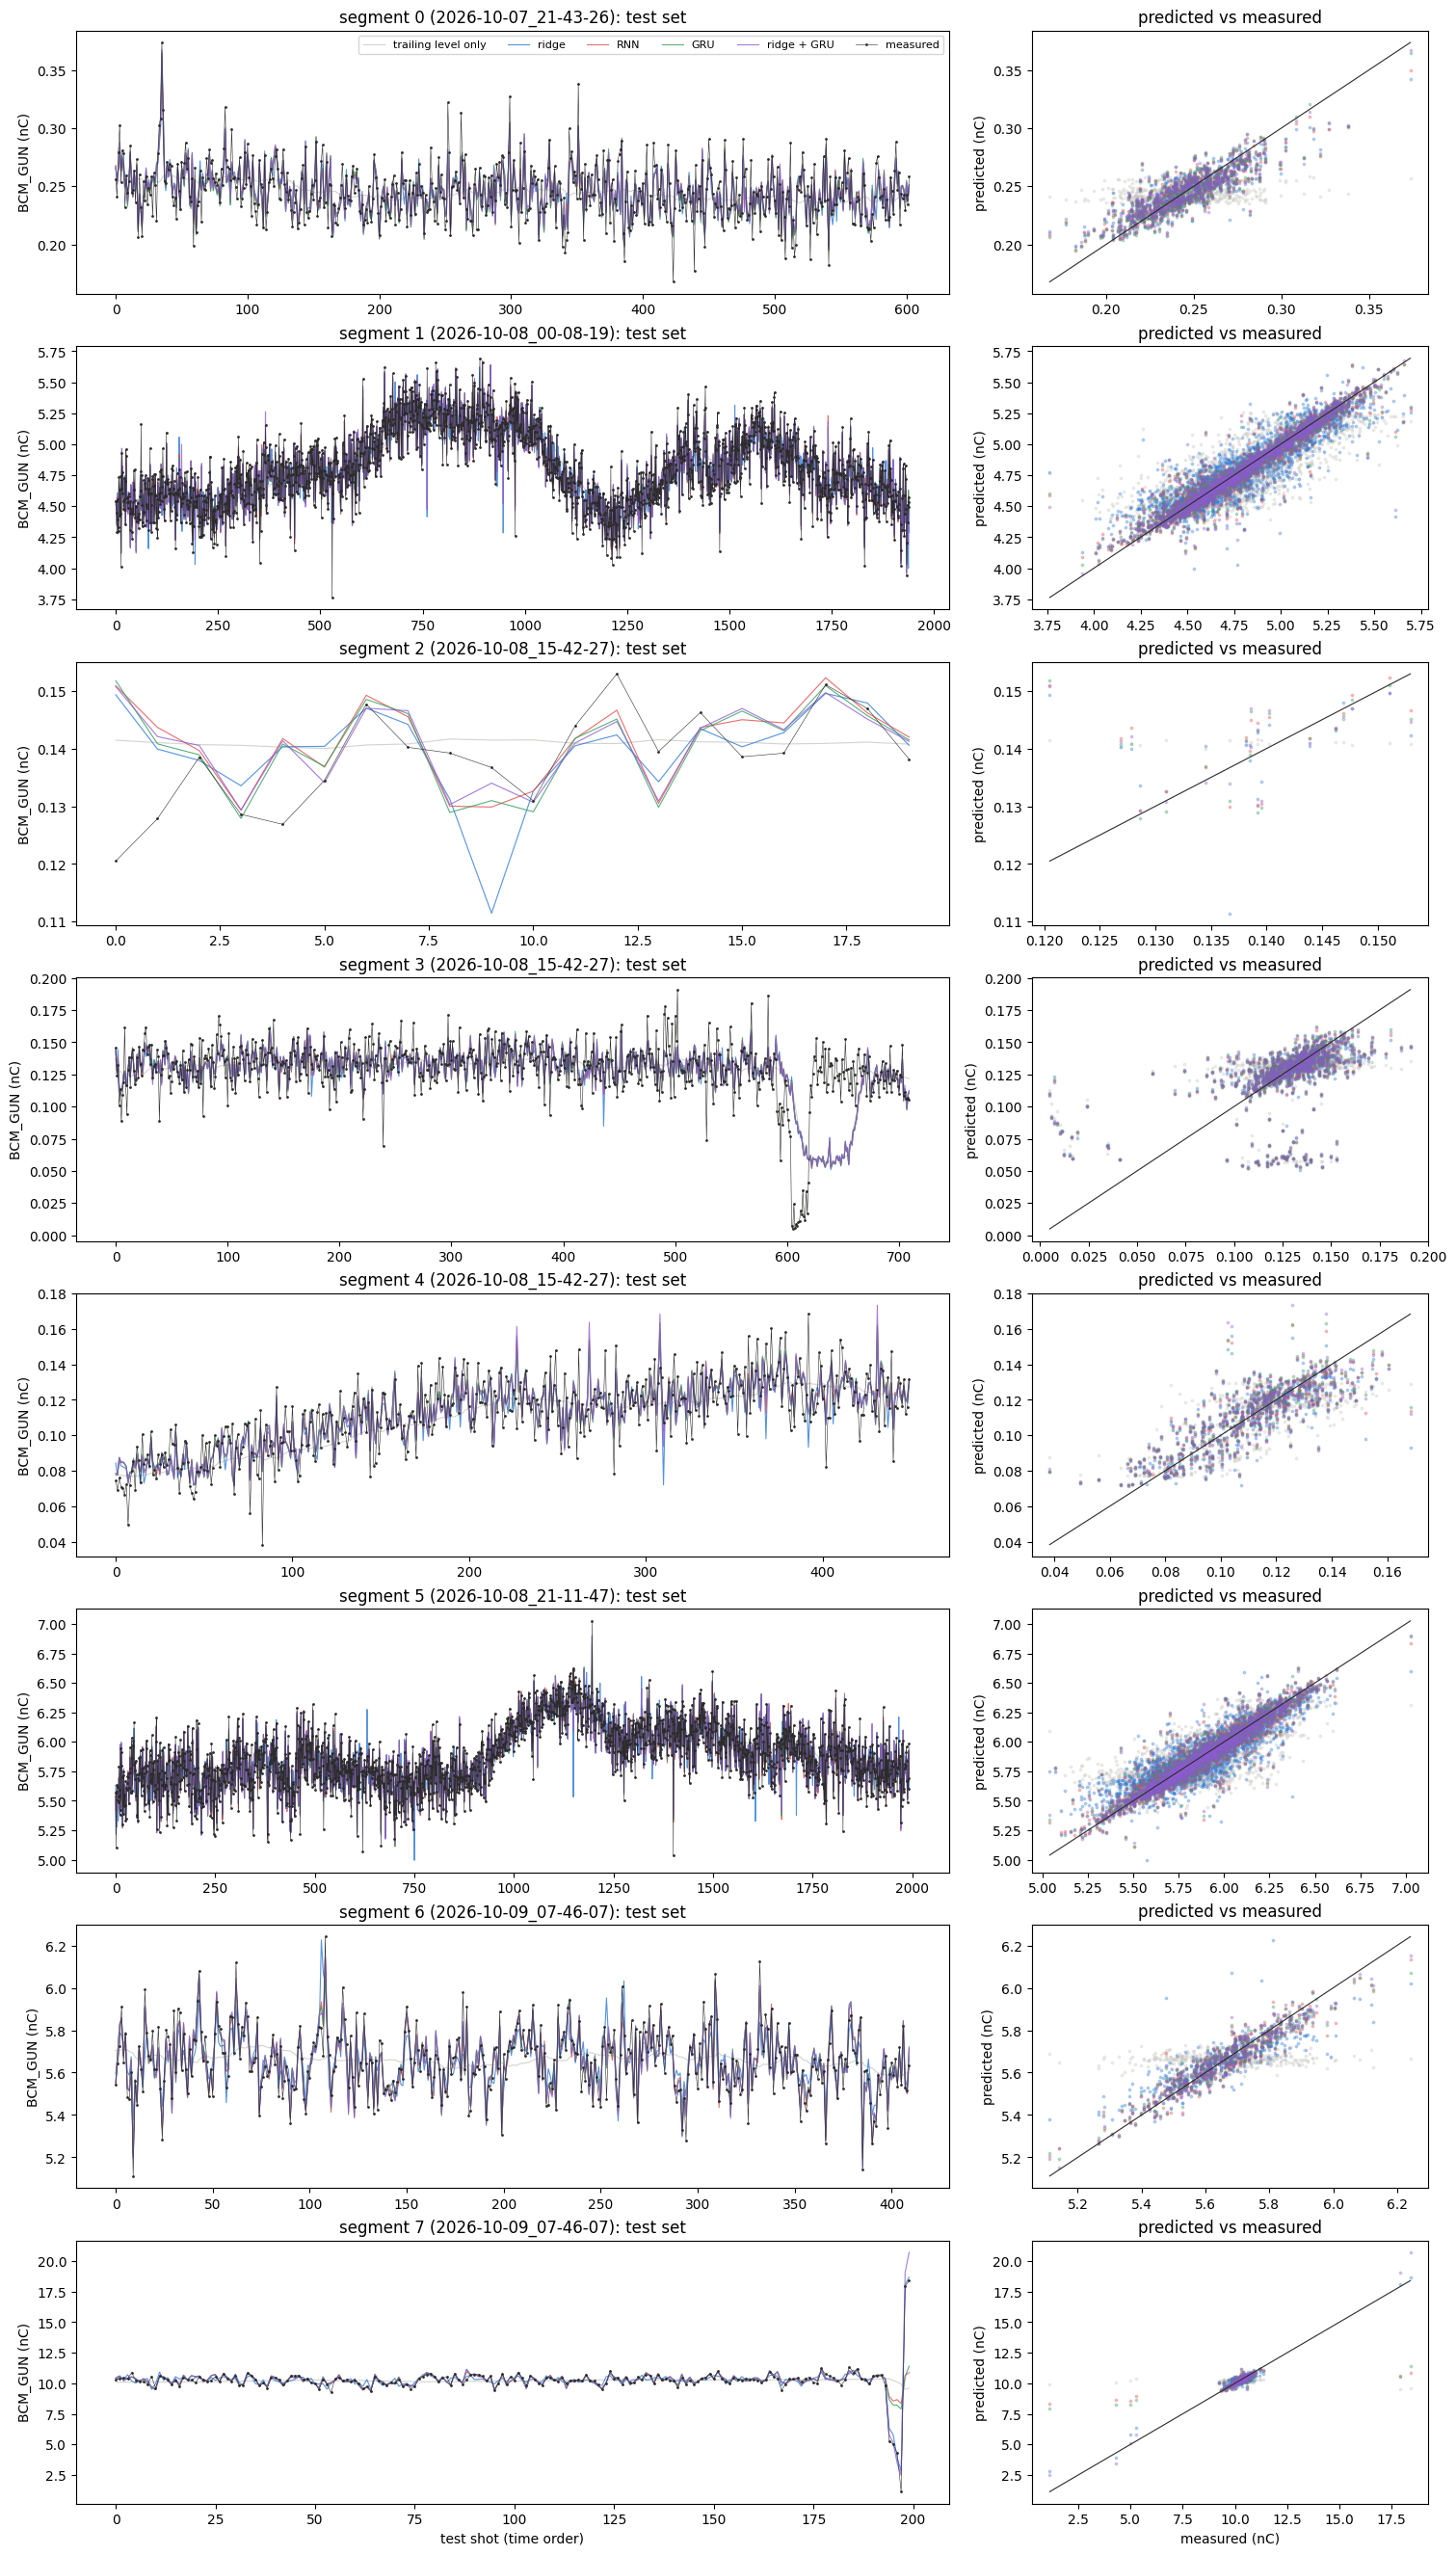

In [12]:
COLORS = {"trailing level only": "#c9c7c1", "ridge": "#2a78d6", "RNN": "#e34948", "GRU": "#2e9e5b", "ridge + GRU": "#8e5bd0"}
fig, axes = plt.subplots(len(curves), 2, figsize=(15, 3.3 * len(curves)), gridspec_kw={"width_ratios": [2.2, 1]},
                         layout="constrained", squeeze=False)
for (ax1, ax2), (s, (y, preds)) in zip(axes, sorted(curves.items())):
    shots = np.arange(len(y))
    for name, color in COLORS.items():
        ax1.plot(shots, preds[name], color=color, lw=0.8, alpha=0.8, label=name)
        ax2.scatter(y, preds[name], s=3, color=color, alpha=0.3)
    ax1.plot(shots, y, ".-", color="#2b2b29", lw=0.4, ms=2, label="measured")                             # on top
    ax2.plot([y.min(), y.max()], [y.min(), y.max()], color="#2b2b29", lw=0.8)
    run = manifest["segments"][s]["run"].removeprefix("acquisition_")
    ax1.set(ylabel="BCM_GUN (nC)", title=f"segment {s} ({run}): test set")
    ax2.set(ylabel="predicted (nC)", title="predicted vs measured")
axes[0, 0].legend(fontsize=8, ncols=6)
axes[-1, 0].set_xlabel("test shot (time order)")
axes[-1, 1].set_xlabel("measured (nC)")
plt.show()


## Notes

**These numbers against the script's** (`scripts/jitter_sequence.py`, tables in `scripts/README.md`).

The two agree on the high-charge segments:
- the networks beat the ridge;
- ridge + GRU fixes seg 7 (here 164 pC, against 241 for the ridge and 289 for the GRU).

But every model is weaker here, the ridge most:

| Jitter explained % | seg 1 | seg 5 | seg 3 |
|---|---|---|---|
| ridge, here / script | 35 / 63 | 43 / 74 | 6 / 28 |
| GRU, here / script | 79 / 83 | 78 / 89 | 7 / 28 |

**Why:** the inputs here track the BCM jitter less well. These are the r of each input's fast part with the BCM's,
on the training shots:

| Input | here, high charge (rep. / non-rep.) | script, high charge (rep. / non-rep.) |
|---|---|---|
| lab laser meter | 0.33 / 0.59 | 0.67 / 0.68 |
| camera intensity | 0.41 / 0.45 | 0.71 / 0.61 |
| PGLA_drop / beam-loading step | 0.10 / 0.13 | 0.34 / 0.35 |

**Likely causes:**
- **Alignment:** the laser meter and the RF use the dataset's one-row shift. The scripts put every reading on the
  1.2 s pulse grid from its own time stamp, and the camera from its own cycle stamp.
- **Step:** the scripts use a windowed beam-loading step rather than `PGLA_drop`.
- **Missing inputs:** clex and the laser scope are not in these datasets. clex carries most of the low-charge signal
  (r 0.52), which is why seg 3 is so much weaker here.

**More from the scripts** (`scripts/README.md`):
- **Window length:** `L = 1` does as well as 16 or 64. The gain over the ridge is the non-linearity, not the memory.
- **Past BCM readings** as an extra input add at most 3 %.
- **BCM noise floor** (`scripts/bcm_noise_floor.py`): about half of the low-charge jitter is the BCM's own noise, and
  at high charge it is 0.5–1 % of the level. There, the GRU was at the floor on segs 0, 4 and 6.
- **More inputs:** the laser pulse shape and the RF flat tops add nothing (`scripts/jitter_input_screen.py`).
